# Ekofisk Deep Azimuthal Resistivity Data Release

This release contains measurement-while-drilling (MWD) azimuthal resistivity and geosignal data from ten horizontal wellbores in the Ekofisk field, Norwegian North Sea (block 2/4). The data are phase and attenuation resistivity at three frequencies (2 MHz, 500 kHz and 125 kHz) and several transmitter–receiver spacings, with geosignals and 32-bin azimuthal images. Each run also includes composite logs and the well path from DISKOS, Norway's national subsurface data repository, all on one measured-depth index.

## Motivation

Deep azimuthal resistivity is widely used to map boundaries and steer wells. However, few public datasets contain the multi-frequency, multi-spacing and azimuthal measurements that inversion needs. We release these data to:

- **Build and test new inversion algorithms** on field measurements rather than synthetic data alone.
- **Provide a shared benchmark**, so different inversion workflows can be run on the same wells and their results compared and reproduced.

Each run includes the image channels, conventional logs and well trajectory, so a full inversion can be set up from one file.

This notebook describes what is delivered, then opens a DLIS file, inspects its channels, plots conventional logs against measured depth, and provides an interactive viewer for the azimuthal image channels.

## What is included

Each of the eleven delivered DLIS files represents one wellbore run. The two 2/4-Z-25 runs remain separate files; they have not been spliced together. Files contain:

- **New MWD measurements:** averaged resistivity (`AR*`), azimuthal resistivity (`ZR*`), and geosignal (`ZG*`) channels, including azimuthal image channels with 32 bins per depth sample. 2/4-VB-5 H T5 and 2/4-VC-2 Y3H have no `ZG` data.
- **DISKOS composite logs:** where available, gamma ray (`GR`), deep and medium resistivity (`RDEP`, `RMED`), density (`DEN`, `DENC`), neutron (`NEU`), photoelectric factor (`PEF`), caliper (`CALI`), bit size (`BS`), rate of penetration (`ROP`), and acoustic (`AC`/`ACS`) measurements.
- **DISKOS well path:** measured-depth-aligned `TVD`, `TVDSS`, `INC`, `AZI`, `UTMX`, and `UTMY` values.

All curves share the file's `DEPT` measured-depth index. The file names identify the well/run and the delivered measured-depth interval in feet.

| Wellbore / run | DLIS file |
|---|---|
| 2/4-VB-5 H T5 | `2_4-VB-5_H_T5_13255-17430ft_RES_GEOSIGNAL.dlis` |
| 2/4-VC-1 H-T2 | `2_4-VC-1_H-T2_11410-15238ft_RES_GEOSIGNAL.dlis` |
| 2/4-VC-2 Y3H | `2_4-VC-2_Y3H_16634-17888ft_RES_GEOSIGNAL.dlis` |
| 2/4-VC-3 H | `2_4-VC-3_H_11330-15215ft_RES_GEOSIGNAL.dlis` |
| 2/4-Z-6 | `2_4-Z-6_16954-20950ft_RES_GEOSIGNAL.dlis` |
| 2/4-Z-19 | `2_4-Z-19_18580-24394ft_RES_GEOSIGNAL.dlis` |
| 2/4-Z-20 | `2_4-Z-20_18840-23791ft_RES_GEOSIGNAL.dlis` |
| 2/4-Z-25, run 1 | `2_4-Z-25_20156-21218ft_RES_GEOSIGNAL.dlis` |
| 2/4-Z-25, run 2 | `2_4-Z-25_21250-25029ft_RES_GEOSIGNAL.dlis` |
| 2/4-Z-26 | `2_4-Z-26_16630-19918ft_RES_GEOSIGNAL.dlis` |
| 2/4-Z-31 Y1 | `2_4-Z-31_Y1_16790-18703ft_RES_GEOSIGNAL.dlis` |

## File conventions and channel names

The files use DLIS (RP66 v1), with one frame per file. `DEPT` is measured depth (MD) in feet below rotary kelly bushing (RKB), sampled at 0.5 ft. The null sentinel is `-999.25`; this notebook converts it to `NaN` before plotting. Azimuthal image samples are arrays of 32 values at each depth. Coordinate values use ED50 / UTM zone 31N, grid north, in metres. Header values such as surface location, datums, and magnetic information are stored in the DLIS parameter set.

New measurement mnemonics follow `AR`, `ZR`, or `ZG` + frequency + spacing + measurement type. The frequency codes are `H` (2 MHz), `M` (500 kHz), and `L` (125 kHz); the final `P` or `A` denotes phase or attenuation. Optional suffixes identify corrected values (`C`) or top, bottom, left, and right quadrants (`T`, `B`, `L`, `R`). For example, `ZRH16P` is a 2 MHz, 16-inch spacing azimuthal resistivity phase image. Resistivity is in `ohmm`; geosignal is in dB for attenuation (`A`) and degrees for phase (`P`). The original tool-specific provenance and azimuthal bin-zero orientation still need confirmation; do not infer an absolute azimuth orientation from the image alone.

## Processing and terms

The `AR`/`ZR`/`ZG` channels were selected from the original MWD DLIS files and trimmed to the interval with data. DISKOS composite logs and well paths were converted to feet where appropriate and interpolated onto the same depth index. Each run was written as its own DLIS file and checked by reading it back. The companion `explore_dlis.ipynb` documents the processing investigation.

The new measurements (`AR*`, `ZR*`, `ZG*`) are released under the [Norwegian Licence for Open Government Data (NLOD) 2.0](https://data.norge.no/nlod/en/2.0). Terms and attribution for the included DISKOS logs and well paths must be confirmed before redistribution. Add the final authors, affiliation, DOI/citation, acknowledgements, contact details, and tool/bin-orientation provenance when available.

## Explore the files

Run the cells below from top to bottom. Set `DATA_DIR` to the directory containing the `.dlis` files. The notebook lists available files, loads one selected run, displays its channel inventory, plots selected conventional logs and TVD, and lets you choose a well, azimuthal image, companion log, and MD window in the interactive viewer. It visualizes values; it does not modify the source DLIS files.

In [1]:
from functools import lru_cache
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, Normalize
from IPython.display import display
from dlisio import dlis


# Set this to the folder containing the .dlis files, e.g. r"C:\Data\Resistivity_Data_Release"
DATA_DIR = r"/Users/dylanloss/code/VibeCode_Hack/Resist/data"

RELEASE_DIR = Path(DATA_DIR)
files = sorted(RELEASE_DIR.glob("*.dlis"))
if not files:
    raise FileNotFoundError(f"No .dlis files in {RELEASE_DIR.resolve()}. Set DATA_DIR to the folder containing the .dlis files.")

display(pd.DataFrame({"file": [path.name for path in files]}))

Matplotlib is building the font cache; this may take a moment.


,file
0,2_4-VB-5_H_T5_13255-17430ft_RES_GEOSIGNAL.dlis
1,2_4-VC-1_H-T2_11410-15238ft_RES_GEOSIGNAL.dlis
2,2_4-VC-2_Y3H_16634-17888ft_RES_GEOSIGNAL.dlis
3,2_4-VC-3_H_11330-15215ft_RES_GEOSIGNAL.dlis
4,2_4-Z-19_18580-24394ft_RES_GEOSIGNAL.dlis
5,2_4-Z-20_18840-23791ft_RES_GEOSIGNAL.dlis
6,2_4-Z-25_20156-21218ft_RES_GEOSIGNAL.dlis
7,2_4-Z-25_21250-25029ft_RES_GEOSIGNAL.dlis
8,2_4-Z-26_16630-19918ft_RES_GEOSIGNAL.dlis
9,2_4-Z-31_Y1_16790-18703ft_RES_GEOSIGNAL.dlis


## 1. Choose and load a run

The first code cell searches `RELEASE_DIR` for top-level `.dlis` files and displays the filenames. Before running it, set `DATA_DIR` to the folder where you saved the `.dlis` files. The error message reports the directory it searched if no files were found.

This cell selects `files[0]` as the example run. To inspect another file, use a different zero-based list position (for example, `files[1]` selects the second listed file), then rerun the load cell and the downstream display/plot cells. Each file corresponds to a run, not necessarily a unique well; in particular, the two Z-25 runs are separate.

In [2]:
@lru_cache(maxsize=4)
def load_well(path):
    # Each delivered file contains one logical file and one depth-indexed frame.
    with dlis.load(str(path)) as logical_files:
        logical_file = logical_files[0]
        frame = logical_file.frames[0]
        values = frame.curves()
        md = values["DEPT"].astype(float)
        curves, images, channel_rows = {}, {}, []
        for channel in frame.channels:
            if channel.name == "DEPT":
                continue
            samples = values[channel.name].astype(float)
            # DLIS uses this numeric sentinel for missing samples; NaN is easier to plot and filter.
            samples[samples == -999.25] = np.nan
            if samples.ndim == 1:
                curves[channel.name] = samples
            else:
                # Multi-dimensional samples are the azimuthal image channels (typically 32 bins).
                images[channel.name] = samples
            channel_rows.append({"channel": channel.name, "units": channel.units,
                                 "dimension": "x".join(map(str, channel.dimension)),
                                 "description": str(channel.long_name)})
        well_name = logical_file.origins[0].well_name
    return {"well_name": well_name, "md": md, "images": images,
            "logs": pd.DataFrame(curves, index=pd.Index(md, name="MD_ft")),
            "channels": pd.DataFrame(channel_rows)}


path = files[0]
well = load_well(path)
well_name, md, logs, images, channels = (well[key] for key in ("well_name", "md", "logs", "images", "channels"))
print(f"{well_name} | {path.name}")
print(f"{md[0]:.1f}-{md[-1]:.1f} ft MD | {len(md)} samples")

2/4-VB-5 H T5 | 2_4-VB-5_H_T5_13255-17430ft_RES_GEOSIGNAL.dlis
13255.0-17430.5 ft MD | 8352 samples


## 2. Inspect the channel inventory

This table is read from the selected DLIS frame. `channel` is the stored mnemonic, `units` gives the recorded unit string, `dimension` describes the sample shape, and `description` is the channel's long name when present. A dimension of `1` is a scalar curve indexed by MD; a dimension of `32` is a 32-bin azimuthal image at each MD sample. Channel availability varies by run, so use the table rather than assuming every mnemonic is present. The `DEPT` index is handled separately and is not repeated in this table.

In [3]:
display(channels)

,channel,units,dimension,description
0,ARH16PC,ohmm,1,ARH16PC/Avg 16in 2M Ph Res Cor
1,ARH16AC,ohmm,1,ARH16AC/Avg 16in 2M At Res Cor
2,ARM16PC,ohmm,1,ARM16PC/Avg 16in 500k Ph Res Cor
3,ARM16AC,ohmm,1,ARM16AC/Avg 16in 500k At Res Cor
4,ARH32PC,ohmm,1,ARH32PC/Avg 32in 2M Ph Res Cor
...,...,...,...,...
123,TVDSS,ft,1,True vertical depth subsea (DISKOS well path)
124,INC,deg,1,Inclination (DISKOS well path)
125,AZI,deg,1,Azimuth (grid north) (DISKOS well path)
126,UTMX,m,1,UTM easting (ED50 / UTM 31N) (DISKOS well path)


## 3. Compare conventional logs and well path

The example plot uses measured depth on the shared horizontal axis. It draws gamma ray (`GR`) when available, deep/medium resistivity (`RDEP`/`RMED`) when present, and true vertical depth (`TVD`) when present. Missing curves are simply omitted, which lets the same cell work across runs with different channel sets.

Resistivity is plotted on a logarithmic vertical scale because values commonly span orders of magnitude; zero and negative values are excluded from that plot because they cannot be represented on a log axis. TVD is inverted so depth increases downward. The labels show the release units: gamma ray in gAPI, resistivity in ohm metres (`ohmm`), and TVD in feet relative to RKB. The horizontal axis remains MD in feet, so MD and TVD should not be read as interchangeable depth references.

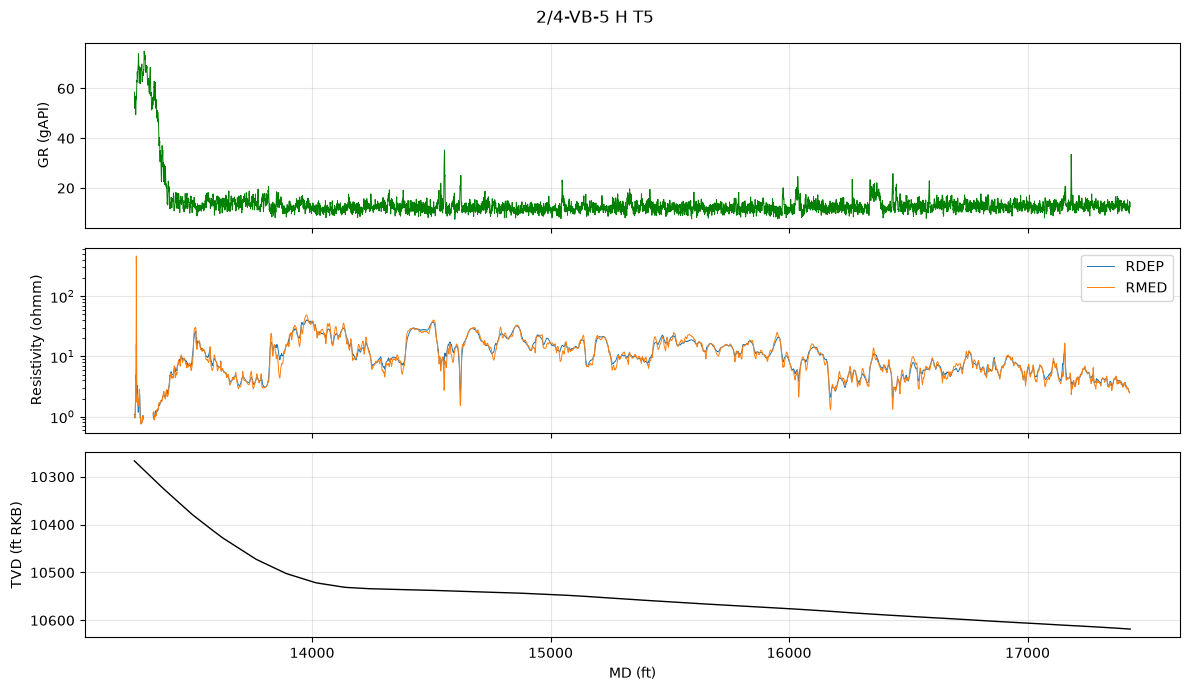

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)

if "GR" in logs:
    axes[0].plot(logs.index, logs["GR"], color="green", linewidth=0.7)
axes[0].set_ylabel("GR (gAPI)")

resistivity = [name for name in ("RDEP", "RMED") if name in logs]
for name in resistivity:
    axes[1].plot(logs.index, logs[name].where(logs[name] > 0), linewidth=0.7, label=name)
axes[1].set_yscale("log")
axes[1].set_ylabel("Resistivity (ohmm)")
if resistivity:
    axes[1].legend()

if "TVD" in logs:
    axes[2].plot(logs.index, logs["TVD"], color="black", linewidth=1)
axes[2].invert_yaxis()
axes[2].set_ylabel("TVD (ft RKB)")
axes[2].set_xlabel("MD (ft)")

for axis in axes:
    axis.grid(alpha=0.3)
fig.suptitle(well_name)
fig.tight_layout()
plt.show()

## 4. Explore an azimuthal image

The controls choose a run, an azimuthal image channel, a scalar log to show above it, and an MD interval. The log defaults to `RDEP` (falling back to `GR` if absent). Changing the run refreshes the available image/log choices and resets the interval to that run's full depth range.


The colour limits are calculated once from the full selected image (2nd–98th percentiles), so zooming the MD slider does not rescale colours. Resistivity images use logarithmic colour scaling and other units use linear scaling. 

In [6]:
import ipywidgets as w


def colour_scale(values, units):
    # Fix limits from the full image so colour meaning stays stable while zooming by MD.
    valid = values[np.isfinite(values) & ((values > 0) if units == "ohmm" else True)]
    if not valid.size:
        return None
    low, high = np.percentile(valid, [2, 98])
    if low == high:
        low, high = (low / 1.1, high * 1.1) if units == "ohmm" else (low - 0.5, high + 0.5)
    return LogNorm(low, high) if units == "ohmm" else Normalize(low, high)


def smooth_image(image, md, md_range, log_values, columns=1200, bins=128):
    keep = (md >= md_range[0]) & (md <= md_range[1])
    image, md = image[keep], md[keep]
    if log_values:
        image = np.log10(np.where(image > 0, image, np.nan))
    # Average before resampling so long intervals do not alias when squeezed into the plot width.
    window = max(1, len(md) // columns)
    image = pd.DataFrame(image).rolling(window, center=True, min_periods=1).mean().to_numpy()
    display_md = np.linspace(md[0], md[-1], columns)
    image = np.column_stack([np.interp(display_md, md, values) for values in image.T])
    # Azimuth is circular, so the last bin interpolates into the first.
    n_bins = image.shape[1]
    position = (np.arange(bins) + 0.5) * n_bins / bins - 0.5
    lower = np.floor(position).astype(int)
    weight = position - lower
    image = image[:, lower % n_bins] * (1 - weight) + image[:, (lower + 1) % n_bins] * weight
    return (10 ** image if log_values else image), display_md


def show_image(well, image_name, log_name, md_range):
    if not well["images"]:
        print("No azimuthal images in this file.")
        return
    if image_name not in well["images"] or log_name not in well["logs"]:
        return
    unit_of = well["channels"].set_index("channel")["units"]
    image, units, md = well["images"][image_name], unit_of[image_name], well["md"]
    scale = colour_scale(image, units)
    if scale is None:
        print(f"{image_name}: no valid values to plot.")
        return
    display_image, display_md = smooth_image(image, md, md_range, units == "ohmm")
    fig, (log_axis, image_axis) = plt.subplots(2, 1, figsize=(12, 5), sharex=True,
                                               gridspec_kw={"height_ratios": [1, 2]})
    log = well["logs"][log_name]
    if unit_of[log_name] == "ohmm":
        log = log.where(log > 0)
        log_axis.set_yscale("log")
    log_axis.plot(log.index, log, color="black", linewidth=0.7)
    log_axis.set_ylabel(f"{log_name} ({unit_of[log_name]})")
    log_axis.grid(alpha=0.3)
    plot = image_axis.imshow(display_image.T, aspect="auto",
                             extent=[display_md[0], display_md[-1], image.shape[1], 0],
                             cmap="jet", norm=scale, interpolation="bilinear")
    image_axis.set(xlabel="MD (ft)", ylabel="Azimuthal bin", xlim=md_range)
    fig.colorbar(plot, ax=[log_axis, image_axis], label=f"{image_name} ({units})")
    fig.suptitle(well["well_name"])
    plt.show()


def pick(options, *preferred):
    return next((name for name in preferred if name in options), options[0] if options else None)


well_dd = w.Dropdown(options=[(p.name, p) for p in files], value=path, description="Well",
                     layout=w.Layout(width="500px"))
image_dd = w.Dropdown(description="Image")
log_dd = w.Dropdown(description="Log")
md_slider = w.FloatRangeSlider(step=0.5, description="MD (ft)", continuous_update=False,
                               readout_format=".0f", layout=w.Layout(width="800px"))
plot_area = w.Output()
updating = False


def redraw(*_):
    if updating:
        return
    with plot_area:
        plot_area.clear_output(wait=True)
        show_image(load_well(well_dd.value), image_dd.value, log_dd.value, md_slider.value)


def on_well(*_):
    global updating
    updating = True
    selected = load_well(well_dd.value)
    previous_image, previous_log = image_dd.value, log_dd.value
    image_dd.options = sorted(selected["images"])
    image_dd.value = pick(image_dd.options, previous_image)
    log_dd.options = [name for name in selected["logs"] if selected["logs"][name].notna().any()]
    log_dd.value = pick(log_dd.options, previous_log, "RDEP", "GR")
    low, high = selected["md"][0], selected["md"][-1]
    # Temporarily widen the slider bounds so its minimum never exceeds its maximum.
    md_slider.max = max(high, md_slider.max)
    md_slider.min = low
    md_slider.max = high
    md_slider.value = (low, high)
    updating = False
    redraw()


well_dd.observe(on_well, "value")
for widget in (image_dd, log_dd, md_slider):
    widget.observe(redraw, "value")

display(w.VBox([well_dd, w.HBox([image_dd, log_dd]), md_slider, plot_area]))
on_well()